**PARTE 1**

Cargar MNIST

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False)
x = mnist.data.astype('float32')
y = mnist.target.astype('int32')
print(x.shape, y.shape)

(70000, 784) (70000,)


Función de preprocesamiento

In [3]:
def preprocesar_formulario(img):
    #1.Escala de grises
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    gris = cv2.GaussianBlur(gris, (3, 3), 0)

    #2.Binarización: dígito blanco, fondo negro
    _, binaria = cv2.threshold(gris, 0, 255,
                               cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    #3.Segmentación por contornos (de izquierda a derecha)
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)
    cajas = sorted([cv2.boundingRect(c) for c in contornos], key=lambda b: b[0])

    digitos = []
    for (x0, y0, w, h) in cajas:
        if w * h < 100:          #ignorar ruido
            continue
        recorte = binaria[y0:y0+h, x0:x0+w]

        #4.Redimensionar a 20x20 manteniendo proporción y centrar en 28x28
        escala = 20 / max(w, h)
        recorte = cv2.resize(recorte, (max(1, int(w*escala)), max(1, int(h*escala))))
        lienzo = np.zeros((28, 28), dtype=np.uint8)
        yo = (28 - recorte.shape[0]) // 2
        xo = (28 - recorte.shape[1]) // 2
        lienzo[yo:yo+recorte.shape[0], xo:xo+recorte.shape[1]] = recorte

        #5.Normalización
        digitos.append(lienzo.astype('float32') / 255.0)

    return np.array(digitos).reshape(-1, 28, 28, 1), binaria

Formulario simulado (datos ficticios) para probar

In [4]:
def crear_formulario(indices):
    ancho = 70 * len(indices) + 40
    hoja = np.full((120, ancho), 255, dtype=np.uint8)      #papel blanco
    for k, i in enumerate(indices):
        digito = 255 - x[i].reshape(28, 28).astype(np.uint8)  #tinta oscura
        digito = cv2.resize(digito, (56, 56))
        hoja[32:88, 20 + 70*k : 20 + 70*k + 56] = digito
    return cv2.GaussianBlur(hoja, (3, 3), 0)

indices = [0, 1, 2, 3, 4]
formulario = crear_formulario(indices)
digitos, binaria = preprocesar_formulario(formulario)
print('Dígitos segmentados:', digitos.shape)
print('Etiquetas reales:', y[indices])

Dígitos segmentados: (5, 28, 28, 1)
Etiquetas reales: [5 0 4 1 9]


Resultado

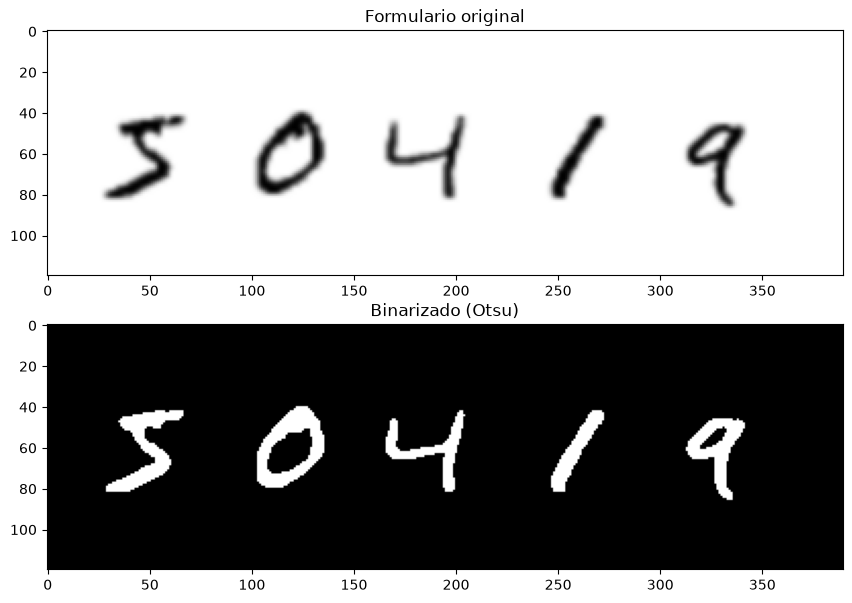

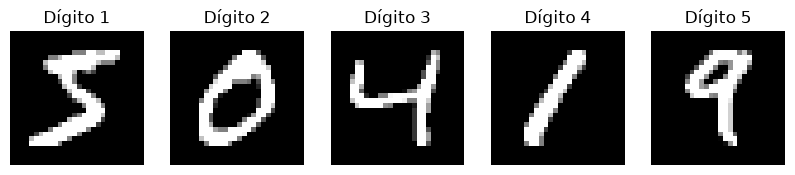

In [20]:
plt.figure(figsize=(12, 7))
plt.subplot(2, 1, 1); plt.imshow(formulario, cmap='gray'); plt.title('Formulario original')
plt.subplot(2, 1, 2); plt.imshow(binaria, cmap='gray'); plt.title('Binarizado (Otsu)')
plt.show()

plt.figure(figsize=(10, 2))
for i in range(len(digitos)):
    plt.subplot(1, len(digitos), i + 1)
    plt.imshow(digitos[i].reshape(28, 28), cmap='gray')
    plt.title(f'Dígito {i+1}'); plt.axis('off')
plt.show()

**PARTE 2**

Partición y normalización

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)

# Normalización: los píxeles pasan de 0-255 a 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0
print(x_train.shape, x_test.shape)

(56000, 784) (14000, 784)


Modelo 1: Red neuronal densa (estilo taller RNA_003)

Las imágenes ya están aplanadas (784 valores) y se usan dos capas densas con ReLU.

In [7]:
import tensorflow as tf

modelo1 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(784,)),   #las imágenes ya están aplanadas
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),
])
modelo1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
modelo1.fit(x_train, y_train, epochs=10)

pred_1 = modelo1.predict(x_test).argmax(1)
acc_1 = accuracy_score(y_test, pred_1)
print('Modelo 1 - Red densa:', acc_1)
print(classification_report(y_test, pred_1))

Epoch 1/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9257 - loss: 0.2514
Epoch 2/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9680 - loss: 0.1036
Epoch 3/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9784 - loss: 0.0705
Epoch 4/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9838 - loss: 0.0520
Epoch 5/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9875 - loss: 0.0391
Epoch 6/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9900 - loss: 0.0324
Epoch 7/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9911 - loss: 0.0274
Epoch 8/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9924 - loss: 0.0228
Epoch 9/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9930 - loss: 0.0205
Epoch 10/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9942 - loss: 0.0173
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Modelo 1 - Red densa: 0.9749285714285715
              precision    recall  f1

Modelo 2: Red neuronal densa con EarlyStopping

Red más pequeña que se entrena hasta que la pérdida deja de mejorar.

In [8]:
modelo2 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),
])
modelo2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='loss',
    patience=3,
    restore_best_weights=True,
    min_delta=0.001
)

modelo2.fit(x_train, y_train, epochs=500, callbacks=[early_stop])

pred_2 = modelo2.predict(x_test).argmax(1)
acc_2 = accuracy_score(y_test, pred_2)
print('Modelo 2 - Red densa con EarlyStopping:', acc_2)
print(classification_report(y_test, pred_2))

Epoch 1/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9123 - loss: 0.3075
Epoch 2/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9586 - loss: 0.1386
Epoch 3/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9699 - loss: 0.0993
Epoch 4/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9764 - loss: 0.0773
Epoch 5/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9813 - loss: 0.0619
Epoch 6/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9847 - loss: 0.0501
Epoch 7/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9873 - loss: 0.0416
Epoch 8/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9896 - loss: 0.0342
Epoch 9/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9912 - loss: 0.0291
Epoch 10/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9913 - loss: 0.0269
Epoch 11/500
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9926 - loss: 0.0231
Epoch 12/500
1750/1

**PARTE 3**

Modelo 3: Red neuronal convolucional (CNN)

Preparar las imágenes para la CNN

In [9]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

x_train_c = x_train.reshape(-1, 28, 28, 1)
x_test_c  = x_test.reshape(-1, 28, 28, 1)

Arquitectura de la CNN

In [10]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28,28,1,)),
    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,106 (109.79 KB)

 Trainable params: 28,106 (109.79 KB)

 Non-trainable params: 0 (0.00 B)

Entrenar con EarlyStopping

In [11]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='loss', patience=3, restore_best_weights=True)

historial = model.fit(x_train_c, y_train, epochs=20, callbacks=[early_stop])

Epoch 1/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9146 - loss: 0.2731
Epoch 2/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9716 - loss: 0.0917
Epoch 3/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9787 - loss: 0.0686
Epoch 4/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9830 - loss: 0.0559
Epoch 5/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9866 - loss: 0.0466
Epoch 6/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9890 - loss: 0.0389
Epoch 7/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9900 - loss: 0.0330
Epoch 8/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9914 - loss: 0.0279
Epoch 9/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9924 - loss: 0.0243
Epoch 10/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9926 - loss: 0.0230
Epoch 11/20
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9938 - loss: 0.0197
Epoch 12/20
1750/17

Validación cruzada simple

In [12]:
from sklearn.model_selection import KFold

x_cv, y_cv = x_train_c[:6000], y_train[:6000]   #subconjunto para que sea rápido
kf = KFold(n_splits=3, shuffle=True, random_state=42)

precisiones = []
for entrenar, validar in kf.split(x_cv):
    m = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(28,28,1,)),
        tf.keras.layers.Conv2D(16, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m.fit(x_cv[entrenar], y_cv[entrenar], epochs=5, verbose=0)
    _, acc = m.evaluate(x_cv[validar], y_cv[validar], verbose=0)
    precisiones.append(acc)
    print('Precisión de esta parte:', acc)

print('Promedio:', np.mean(precisiones))

Precisión de esta parte: 0.9524999856948853
Precisión de esta parte: 0.9629999995231628
Precisión de esta parte: 0.9459999799728394
Promedio: 0.9538333217302958


Ajuste de hiperparámetros simple

In [13]:
resultados = {}
for neuronas in [32, 64, 128]:
    m = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(28,28,1,)),
        tf.keras.layers.Conv2D(16, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(neuronas, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m.fit(x_cv[:4000], y_cv[:4000], epochs=5, verbose=0)
    _, acc = m.evaluate(x_cv[4000:], y_cv[4000:], verbose=0)
    resultados[neuronas] = acc
    print('Neuronas:', neuronas, '-> precisión:', acc)

print('Mejor:', max(resultados, key=resultados.get))

Neuronas: 32 -> precisión: 0.9555000066757202
Neuronas: 64 -> precisión: 0.9555000066757202
Neuronas: 128 -> precisión: 0.9645000100135803
Mejor: 128


**PARTE 4**

Evaluación de la CNN en el conjunto de prueba

Predicciones

In [14]:
y_pred = model.predict(x_test_c)
print(y_pred.argmax(1)[:8])   #índice de la máxima probabilidad
print(y_test[:8])             #etiquetas reales

438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
[8 4 8 7 7 0 6 2]
[8 4 8 7 7 0 6 2]


Imágenes con predicción vs. etiqueta reaL

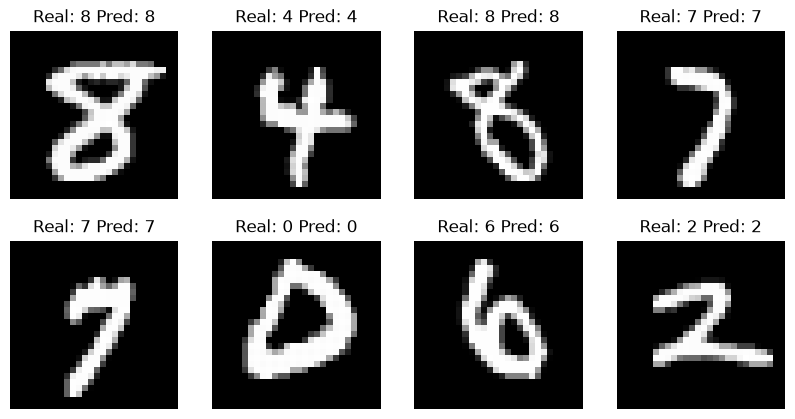

In [15]:
plt.figure(figsize=(10,5))
for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(x_test_c[i].reshape(28,28), cmap='gray')
    plt.title('Real: '+str(y_test[i])+' Pred: '+str(y_pred.argmax(1)[i]))
    plt.axis('off')
plt.show()

precisión y reporte

In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print(accuracy_score(y_test, y_pred.argmax(1)))
print(classification_report(y_test, y_pred.argmax(1)))
print(confusion_matrix(y_test, y_pred.argmax(1)))

0.9816428571428572
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1343
           1       1.00      0.99      0.99      1600
           2       0.98      0.97      0.97      1380
           3       0.99      0.97      0.98      1433
           4       0.98      0.99      0.98      1295
           5       0.99      0.97      0.98      1273
           6       0.99      0.99      0.99      1396
           7       0.96      0.99      0.98      1503
           8       0.96      0.99      0.97      1357
           9       0.98      0.98      0.98      1420

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000

[[1330    0    1    0    1    2    2    1    2    4]
 [   0 1580    3    1    4    0    2    7    1    2]
 [   0    2 1335    2    3    1    4   25    8    0]
 [   0    0   11 1390    0    5    0   19    6    2]
 [   3    

Errores del modelo

Cantidad de errores: 257 de 14000


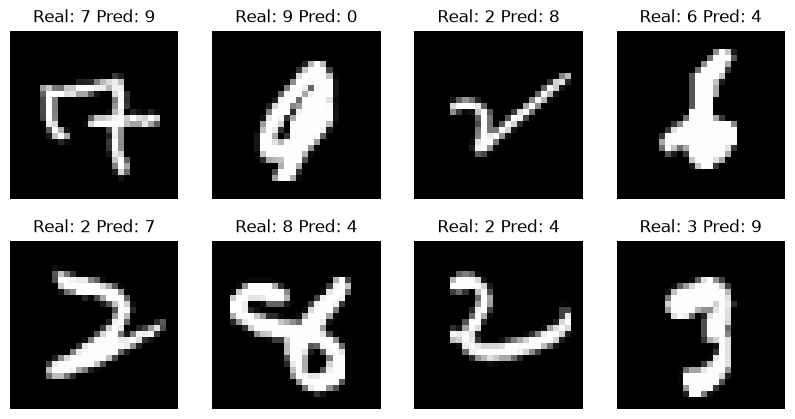

In [17]:
pred_final = y_pred.argmax(1)
errores = np.where(pred_final != y_test)[0]
print('Cantidad de errores:', len(errores), 'de', len(y_test))

plt.figure(figsize=(10,5))
for k in range(8):
    i = errores[k]
    plt.subplot(2,4,k+1)
    plt.imshow(x_test_c[i].reshape(28,28), cmap='gray')
    plt.title('Real: '+str(y_test[i])+' Pred: '+str(pred_final[i]))
    plt.axis('off')
plt.show()

Comparación de los 3 modelos

In [18]:
acc_cnn = accuracy_score(y_test, pred_final)

print('--- Comparación de los 3 modelos ---')
print('Modelo 1 - Red densa:', acc_1)
print('Modelo 2 - Red densa con EarlyStopping:', acc_2)
print('Modelo 3 - CNN:', acc_cnn)

--- Comparación de los 3 modelos ---
Modelo 1 - Red densa: 0.9749285714285715
Modelo 2 - Red densa con EarlyStopping: 0.9677857142857142
Modelo 3 - CNN: 0.9816428571428572


Navegador

In [21]:
import os
os.makedirs('modelos', exist_ok=True)

modelo1.save('modelos/modelo1.keras')
modelo2.save('modelos/modelo2.keras')
model.save('modelos/modelo3_cnn.keras')
print('Modelos guardados en la carpeta modelos')

Modelos guardados en la carpeta modelos
